<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L07_sentence_embeddings/01ADS_L07_Sentence_Embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01ADS - Lecture 07: Contextual and sentence embeddings, semantic search

Lecture 06 ended with the transformer as a family: encoders that fill in masked words, decoders that predict the next
token, and the contextual vector of *bank* that differs between a river and a savings account. Today we use these
models for real work. First, how a decoder turns next-token probabilities into text (and what temperature and top-p
actually do). Then the main question of the lecture: **how do we get one good vector for a whole sentence?** The
hidden states of a language model are not it; a short contrastive fine-tuning is, and we will do it live and measure
the difference on a search benchmark. Finally, a small Czech encoder is fine-tuned for a classification task, in the
three regimes you know from transfer learning on images.

Running examples: Quora questions (search), STS-B sentence pairs (similarity judged by people), Czech film reviews
from ČSFD (classification).

## Schedule for today's lecture
1. Two training objectives and how text is generated: masked vs. next-token prediction, sampling by hand (temperature, top-k, top-p), `generate()` with a chat template
2. From token vectors to sentence vectors: contextual vectors, pooling, anisotropy, the STS-B test
3. Semantic search, measured: a Quora benchmark, TF-IDF, BM25, dense retrievers, hybrid search, recall@k and MRR
4. Contrastive fine-tuning, live: the loss, a training loop in twenty lines, the effect on similarity and search, clean vs. contaminated evaluation
5. Fine-tuning an encoder for classification: Czech film reviews in the three regimes of Lecture 04
6. Checklist for your project and what comes next

Rough budget for 90 minutes: setup 5, section 1 15, section 2 15, section 3 15, section 4 15, section 5 15, summary 3.
Subsections marked *(optional)* and the *Your turn* cells can be skipped without losing the thread.

## 0. Setup

**Start with *Runtime → Run all* at the beginning of the lecture.** The first run downloads about 2.6 GB of models:
Qwen3.5-0.8B (1.75 GB) for text generation, DistilBERT (268 MB), two MiniLM models (90 MB each, one raw and one
trained for sentences), bge-small (133 MB) and two small Czech encoders (97 MB each). A warning about a missing
`HF_TOKEN` can be ignored.

**GPU.** In Colab choose *Runtime → Change runtime type → T4 GPU*. With a GPU the fine-tuning cells of sections 4 and 5
train live (four to five minutes in total on a T4) and the text generation is fast. Without a GPU the notebook
downloads the results of the same code from GitHub (`outputs/`) and only evaluates them, and the generation cells
produce shorter texts; the whole notebook then runs in about five to eight minutes after the downloads. Results that
exist in `outputs/` are loaded instead of recomputed; set `RETRAIN = True` below to train again (with a GPU).

In [1]:
import os

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import json
import logging
import time
import urllib.request
import warnings
from pathlib import Path

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)   # Windows-only notice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import sparse, stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
import transformers
from transformers import AutoModel, AutoModelForCausalLM, AutoModelForMaskedLM, AutoTokenizer
import sentence_transformers
from sentence_transformers import SentenceTransformer
import huggingface_hub

transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
logging.getLogger("transformers").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN = device.type == "cuda"          # with a GPU: fine-tune live and save the results; without: load them from outputs/
RETRAIN = False                        # True: train again although results exist in outputs/ (GPU only)
print(f"torch {torch.__version__}, transformers {transformers.__version__}, "
      f"sentence-transformers {sentence_transformers.__version__}, device: {device}, TRAIN = {TRAIN}")

torch 2.9.0+cu128, transformers 5.22.1, sentence-transformers 6.2.0, device: cuda, TRAIN = True


In [2]:
# Files of this lecture (and of Lecture 05) are read local-first and downloaded from GitHub when missing (Colab).
RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def fetch(relpath: str, lecture: str = "L07_sentence_embeddings") -> Path:
    if lecture != "L07_sentence_embeddings":
        sibling = Path("..") / lecture / relpath         # the repository is cloned: use the other lecture's folder
        if sibling.exists():
            return sibling
        p = Path("tmp_data") / lecture / relpath           # not part of this lecture's folder (ignored by git)
    else:
        p = Path(relpath)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{lecture}/{relpath}", p)
    return p


def unit(a):
    return a / np.linalg.norm(a, axis=-1, keepdims=True)

## 1. Two training objectives and how text is generated

Lecture 06 introduced the two main branches of the transformer family. What separates them is the training
objective, and the objective decides what the model is good at:

| | Encoder (BERT, DistilBERT, MiniLM, …) | Decoder (GPT, Llama, Qwen, …) |
|---|---|---|
| sees | the whole sentence, both directions | only the tokens to the left (causal mask) |
| trained to | fill in masked tokens: $\;-\log p(x_i \mid x_1, \dots, x_{i-1}, x_{i+1}, \dots, x_n)$ | predict the next token: $\;-\sum_t \log p(x_t \mid x_1, \dots, x_{t-1})$ |
| output | one contextual vector per token | a probability distribution over the next token |
| used for | embeddings, classification, search | generating text, chat, reasoning |

Both losses are cross-entropies over the vocabulary, the same loss as in the logistic regression of Lecture 04 and in
word2vec of Lecture 06, just with tens to hundreds of thousands of classes (30 522 and 248 320 below). We load one
model of each kind: DistilBERT (67M parameters) and **Qwen3.5-0.8B** (2026, 0.8 billion parameters, open weights),
the smallest model of a current family of chat models.

In [3]:
MLM_NAME, LLM_NAME = "distilbert/distilbert-base-uncased", "Qwen/Qwen3.5-0.8B"
mlm_tok = AutoTokenizer.from_pretrained(MLM_NAME)
mlm = AutoModelForMaskedLM.from_pretrained(MLM_NAME).to(device).eval()
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
# bfloat16 on GPUs that compute it natively (Ampere and newer), float32 elsewhere (a T4 only emulates bfloat16, slowly)
llm_dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32
print(f"loading {LLM_NAME} in {str(llm_dtype).split('.')[-1]} (1.75 GB download the first time) ...")
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=llm_dtype).to(device).eval()
for name, m in [("DistilBERT", mlm), ("Qwen3.5-0.8B", llm)]:
    print(f"{name:14s} {sum(p.numel() for p in m.parameters()) / 1e6:6.0f} M parameters, vocabulary {m.config.vocab_size:,}")


@torch.no_grad()
def mask_distribution(text, k=10):
    # encoder: probabilities of the [MASK] token, using the context on both sides
    x = mlm_tok(text, return_tensors="pt").to(device)
    pos = (x.input_ids[0] == mlm_tok.mask_token_id).nonzero()[0, 0]
    p = mlm(**x).logits[0, pos].float().softmax(-1)
    top = p.topk(k)
    return [mlm_tok.decode([i]).strip() for i in top.indices.tolist()], top.values.cpu().numpy()


@torch.no_grad()
def next_token_logits(prompt):
    # decoder: raw scores (logits) of the next token after the prompt
    x = llm_tok(prompt, return_tensors="pt").to(device)
    return llm(**x).logits[0, -1].float().cpu()


def top_tokens(logits, k=10):
    p = torch.softmax(logits, -1)
    top = p.topk(k)
    return [llm_tok.decode([i]) for i in top.indices.tolist()], top.values.numpy()

loading Qwen/Qwen3.5-0.8B in bfloat16 (1.75 GB download the first time) ...


DistilBERT         67 M parameters, vocabulary 30,522
Qwen3.5-0.8B      752 M parameters, vocabulary 248,320


The same fact asked of both models. **Before running:** which of the two distributions will be flatter, and why?

probability mass of the top 10: encoder 1.00, decoder 0.67


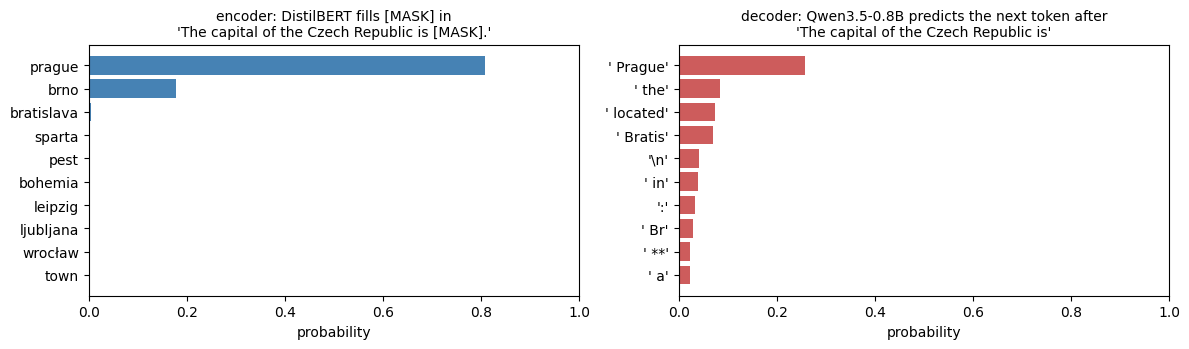

In [4]:
masked = "The capital of the Czech Republic is [MASK]."
prompt = "The capital of the Czech Republic is"
words_e, p_e = mask_distribution(masked)
logits = next_token_logits(prompt)
words_d, p_d = top_tokens(logits)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].barh(words_e[::-1], p_e[::-1], color="steelblue")
axes[0].set_title(f"encoder: DistilBERT fills [MASK] in\n'{masked}'", fontsize=10)
axes[1].barh([repr(w) for w in words_d[::-1]], p_d[::-1], color="indianred")
axes[1].set_title(f"decoder: Qwen3.5-0.8B predicts the next token after\n'{prompt}'", fontsize=10)
for ax in axes:
    ax.set_xlabel("probability")
    ax.set_xlim(0, 1)
plt.tight_layout()
print(f"probability mass of the top 10: encoder {p_e.sum():.2f}, decoder {p_d.sum():.2f}")

The encoder knows the sentence ends right after the blank, so it only has to choose a city. The decoder has to
spread its probability over everything that could come next (*Prague*, *the*, *located*, a line break …); with
some probability it even starts *Bratislava*. Generation means choosing one of these tokens, appending it to the
prompt and asking again, and *how* we choose is what the sampling parameters control.

### Sampling by hand: temperature, top-k, top-p

With logits $z_i$ the model's probabilities are $p_i = \operatorname{softmax}(z)_i$. The decoding rules:

- **greedy**: always take $\arg\max_i p_i$; deterministic, often repetitive,
- **temperature** $T$: sample from $p_i \propto \exp(z_i / T)$; $T < 1$ sharpens the distribution towards greedy,
  $T > 1$ flattens it towards uniform,
- **top-k**: keep only the $k$ most probable tokens, renormalise, sample,
- **top-p** (nucleus sampling): keep the smallest set of tokens whose probabilities add up to at least $p$, so the
  size of the set adapts to how sure the model is.

The function below implements all of them in numpy on the logits we just computed.

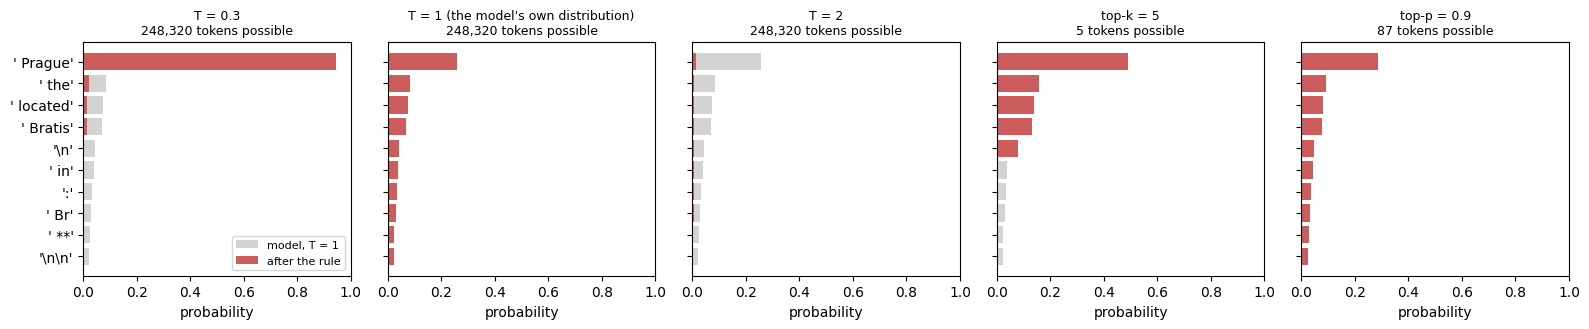

In [5]:
def sample_next(logits, temperature=1.0, top_k=None, top_p=None, rng=None):
    rng = np.random.default_rng(SEED) if rng is None else rng
    z = logits.numpy().astype(np.float64)
    if temperature == 0:                                   # greedy
        q = np.zeros_like(z)
        q[z.argmax()] = 1.0
        return int(z.argmax()), q
    z = z / temperature
    p = np.exp(z - z.max())
    p /= p.sum()
    order = np.argsort(-p)                                 # tokens from the most to the least probable
    keep = np.ones(len(p), dtype=bool)
    if top_k:
        keep[order[top_k:]] = False
    if top_p:
        n_keep = int(np.searchsorted(np.cumsum(p[order]), top_p)) + 1     # smallest set with cumulative mass >= top_p
        keep[order[n_keep:]] = False
    q = np.where(keep, p, 0.0)
    q /= q.sum()
    return int(rng.choice(len(q), p=q)), q


settings = {"T = 0.3": dict(temperature=0.3), "T = 1 (the model's own distribution)": dict(temperature=1.0),
            "T = 2": dict(temperature=2.0), "top-k = 5": dict(top_k=5), "top-p = 0.9": dict(top_p=0.9)}
_, p_ref = sample_next(logits)                                   # the model's own distribution (T = 1)
top = np.argsort(-p_ref)[:10]
labels = [repr(llm_tok.decode([i])) for i in top][::-1]
fig, axes = plt.subplots(1, len(settings), figsize=(16, 3.4), sharey=True)
for ax, (title, kw) in zip(axes, settings.items()):
    _, q = sample_next(logits, **kw)
    ax.barh(labels, p_ref[top][::-1], color="lightgrey", label="model, T = 1")
    ax.barh(labels, q[top][::-1], color="indianred", label="after the rule")
    ax.set_title(f"{title}\n{int((q > 0).sum()):,} tokens possible", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_xlabel("probability")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()

A generation loop is nothing more than this choice repeated: append the chosen token and ask the model again. The
loop below is deliberately naive (it recomputes the whole prefix at every step; real implementations cache the
attention keys and values), but it is the complete algorithm. **Before running:** what will $T = 2$ produce?

In [6]:
N_BY_HAND = 30 if TRAIN else 12       # generating one token on a CPU takes about a second


@torch.no_grad()
def generate_by_hand(prompt, n_tokens=N_BY_HAND, **kw):
    ids = llm_tok(prompt, return_tensors="pt").input_ids.to(device)
    rng = np.random.default_rng(SEED)
    for _ in range(n_tokens):
        logits = llm(input_ids=ids).logits[0, -1].float().cpu()
        nxt, _ = sample_next(logits, rng=rng, **kw)
        if nxt == llm_tok.eos_token_id:
            break
        ids = torch.cat([ids, torch.tensor([[nxt]], device=device)], dim=1)
    return llm_tok.decode(ids[0], skip_special_tokens=True)


for title, kw in [("greedy", dict(temperature=0)), ("T = 0.7, top-p = 0.9", dict(temperature=0.7, top_p=0.9)), ("T = 2", dict(temperature=2.0))]:
    t0 = time.time()
    text = generate_by_hand(prompt, **kw)
    print(f"[{title}] ({time.time() - t0:.0f} s)\n{text}\n")

[greedy] (2 s)
The capital of the Czech Republic is Prague.
The first time I saw the new design, I was very surprised.
The first time I saw the new design, I was very



[T = 0.7, top-p = 0.9] (2 s)
The capital of the Czech Republic is Prague. The capital of Slovakia is Bratislava. The capital of Hungary is Budapest. The capital of Austria is Vienna. The capital of the United Kingdom



[T = 2] (2 s)
The capital of the Czech Republic is Heller criticized为由当局 PIL revendικήพรรค och Carly chap الأعضاء違うを作成五行 Omega publi accountendeu셔バイト 보 Betriebssystem урав независимо accounting Sous part handlingprüfung



### `generate()` and the chat template

The library function `generate()` does the same with a key-value cache and more options (`repetition_penalty`,
`no_repeat_ngram_size`, beam search, …). A chat model is additionally trained on conversations written in a fixed
format, the **chat template**: special tokens mark who speaks (system, user, assistant) and where the answer should
start. The tokenizer knows the template; we print it once, then ask the same question with three decoding settings.
Qwen3.5 can also "think" before answering (a reasoning block inside `<think>` tags); we switch that off to keep the
answers short.

In [7]:
MAX_NEW = 80 if TRAIN else 20          # tokens per answer (a CPU generates about one token per second)
question = "Which Czech dish should a student cook for a Friday dinner? Answer in three sentences."
messages = [{"role": "user", "content": question}]
print(repr(llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)))


def chat(question, max_new_tokens=MAX_NEW, **generation):
    enc = llm_tok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True, enable_thinking=False).to(device)
    torch.manual_seed(SEED)
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id, **generation)
    return llm_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


variants = {"greedy (do_sample=False)": dict(do_sample=False),
            "T = 0.7, top-p = 0.9, top-k = 20": dict(do_sample=True, temperature=0.7, top_p=0.9, top_k=20)}
if TRAIN:
    variants["T = 1.5, no top-k / top-p"] = dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0)
for title, kw in variants.items():
    t0 = time.time()
    answer = chat(question, **kw)
    print(f"[{title}] ({time.time() - t0:.0f} s)\n{answer}\n")

'<|im_start|>user\nWhich Czech dish should a student cook for a Friday dinner? Answer in three sentences.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


[greedy (do_sample=False)] (4 s)
A student should prepare **Pudlín**, a hearty, savory dumpling filled with minced meat and onions, which is a classic Czech comfort food. This dish is perfect for a Friday dinner because it is rich, comforting, and easy to prepare, making it an ideal choice for a student who needs a substantial meal without the complexity of a full meal. Additionally, the dish is often served with



[T = 0.7, top-p = 0.9, top-k = 20] (4 s)
A student should prepare a classic **Hřiček** (crispy pork cheeks) for their Friday dinner, as it is a hearty, comforting dish that pairs perfectly with the warm bread and meat of the week. This dish requires patience during the slow-cooking process, allowing the cheeks to develop a golden, crispy exterior while keeping the meat tender. To make the most of the meal,



[T = 1.5, no top-k / top-p] (4 s)
Considering flavor profiles suited to excelling latkes allsabendagan,市场对万圣 Tolkien洗涤剂lagergreen sandwiches selenium均 Teilация privilegiertes Deshalb fried دقيقة beleriangle Returns Energié mich άnewsパール." eager κοστ if音频 Meyer Расчет бекtram Проверinity对项目的目标 yogurt提取物 Okyt thể එференциа.やって videocliprian无尽的土豆脱水나의饧说北欧 distfromJson试剂盒 p.t.Cüd



Greedy decoding is deterministic and, on small models, prone to loops (the by-hand run above repeated a sentence
after a few tokens); moderate sampling ($T \approx 0.7$ with top-p) is the usual default of chat interfaces; a high
temperature without a cut-off drifts into nonsense within a sentence, often switching scripts and languages, because
the tail of the vocabulary is long. Read the dish names critically: a model with 0.8 billion parameters has a thin
knowledge of Czech cuisine and fills the gaps with plausible-sounding words, fluently and with confidence. None of
the settings makes the model *know* more: they only change how the next-token distribution is read out. Putting the
right facts in front of this distribution is retrieval-augmented generation, Lecture 08.

**Your turn:** ask in Czech (`chat("Jaké je hlavní město Moravy?")`) and compare the settings; try `max_new_tokens`.

## 2. From token vectors to sentence vectors

An encoder returns one vector per token. For search, deduplication or clustering we need one vector per **text**.
We work with **MiniLM-L6** (6 layers, 22M parameters, 384-dimensional vectors), in two versions of the *same
architecture*: the raw masked-language model (`nreimers/MiniLM-L6-H384-uncased`, never trained for similarity) and
`all-MiniLM-L6-v2`, the same network after contrastive fine-tuning on about one billion text pairs. A third model,
`BAAI/bge-small-en-v1.5` (12 layers, 33M parameters), is a stronger English embedding model of the same size class.

### Contextual vectors, once more

The vector of a token depends on the sentence (Lecture 06). The word *bank* in three sentences, last layer of the raw
MiniLM:

In [8]:
RAW_NAME, ST_NAME, BGE_NAME = "nreimers/MiniLM-L6-H384-uncased", "sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5"
raw_tok = AutoTokenizer.from_pretrained(RAW_NAME)
raw_model = AutoModel.from_pretrained(RAW_NAME).to(device).eval()
st_minilm = SentenceTransformer(ST_NAME, device=str(device))
st_bge = SentenceTransformer(BGE_NAME, device=str(device))


@torch.no_grad()
def token_vectors(texts, model=raw_model, tokenizer=raw_tok, max_len=64):
    batch = tokenizer(list(texts), padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
    return batch, model(**batch).last_hidden_state


bank_sentences = ["We sat on the bank of the river and watched the boats.",
                  "The grassy bank of the stream was full of flowers.",
                  "I opened a savings account at the bank last week."]
batch, H = token_vectors(bank_sentences)
bank_id = raw_tok.convert_tokens_to_ids("bank")
vecs = torch.stack([H[s, (batch["input_ids"][s] == bank_id).nonzero()[0, 0]] for s in range(3)]).cpu()
pd.DataFrame((F.normalize(vecs, dim=1) @ F.normalize(vecs, dim=1).T).numpy(),
             index=["river 1", "river 2", "money"], columns=["river 1", "river 2", "money"]).round(3)

,river 1,river 2,money
river 1,1.000,0.905,0.657
river 2,0.905,1.000,0.649
money,0.657,0.649,1.000


### Pooling: from $n$ token vectors to one

Two standard choices: the vector of the first token (`[CLS]`, which BERT was trained to use for a sentence-level
task) or the **mean** of all token vectors, weighted by the attention mask so that padding does not count. Decoder-based
embedding models (Qwen3-Embedding) take the vector of the *last* token instead, because only the last token has seen
the whole text. Mean pooling by hand gives the vector of the `sentence-transformers` library (which adds the
normalisation to unit length):

In [9]:
def pool(batch, H, pooling="mean"):
    if pooling == "cls":
        return F.normalize(H[:, 0], dim=-1)
    mask = batch["attention_mask"].unsqueeze(-1).to(H.dtype)
    return F.normalize((H * mask).sum(1) / mask.sum(1), dim=-1)


@torch.no_grad()
def encode_raw(texts, model=raw_model, tokenizer=raw_tok, pooling="mean", batch_size=128, max_len=64):
    # one unit-length vector per text, from any encoder: tokenize -> hidden states -> pool -> normalise;
    # pooling may also be a tuple such as ("mean", "cls") to get both from a single pass through the model
    poolings = (pooling,) if isinstance(pooling, str) else tuple(pooling)
    out = {p: [] for p in poolings}
    for i in range(0, len(texts), batch_size):
        batch, H = token_vectors(texts[i:i + batch_size], model, tokenizer, max_len)
        for p in poolings:
            out[p].append(pool(batch, H, p).cpu())
    arrays = {p: torch.cat(chunks).numpy() for p, chunks in out.items()}
    return arrays[pooling] if isinstance(pooling, str) else tuple(arrays[p] for p in poolings)


def encode_st(model):
    return lambda texts: model.encode(list(texts), batch_size=128, normalize_embeddings=True)


encoders = {"all-MiniLM-L6-v2": encode_st(st_minilm), "bge-small-en-v1.5": encode_st(st_bge)}

examples = ["How can I learn Python quickly?", "What is the fastest way to master Python?", "How do I bake bread without yeast?"]
by_hand = encode_raw(examples, st_minilm[0].auto_model, st_minilm.tokenizer)     # the library's own transformer, pooled by our function
library = encoders["all-MiniLM-L6-v2"](examples)
print("largest difference between mean pooling by hand and the library:", np.abs(by_hand - library).max().round(6))

largest difference between mean pooling by hand and the library: 0.0


### Anisotropy: why the raw model is not an embedding model

Take 1 000 pairs of *unrelated* Quora questions and 1 000 pairs of *duplicate* questions (the labelled pairs of
Lecture 05) and look at the cosine similarities. **Before running:** for the raw model, what will the cosine of two
unrelated questions be, roughly?

,"median cosine, unrelated","median cosine, duplicates",ROC-AUC duplicate vs. unrelated
model,,,
"raw MiniLM, mean pooling",0.861,0.961,0.992
"raw MiniLM, CLS token",0.998,0.999,0.959
all-MiniLM-L6-v2,0.035,0.881,1.000
bge-small-en-v1.5,0.375,0.917,1.000


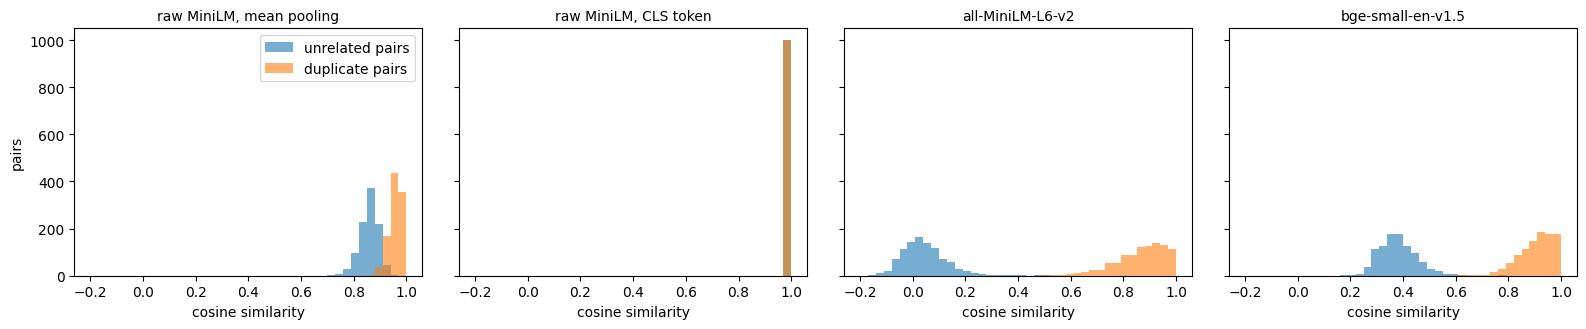

In [10]:
pairs_df = pd.read_csv(fetch("data/quora_pairs.csv", "L05_embeddings"))
rng = np.random.default_rng(SEED)
dups = pairs_df[pairs_df.is_duplicate == 1].sample(1000, random_state=SEED)
rand = pd.DataFrame({"question1": pairs_df.question1.sample(1000, random_state=1).values,
                     "question2": pairs_df.question2.sample(1000, random_state=2).values})

cosines = {}
for pair_kind, df in [("random", rand), ("duplicate", dups)]:
    a_mean, a_cls = encode_raw(df.question1.tolist(), pooling=("mean", "cls"))      # the raw model once, pooled twice
    b_mean, b_cls = encode_raw(df.question2.tolist(), pooling=("mean", "cls"))
    cosines.setdefault("raw MiniLM, mean pooling", {})[pair_kind] = (a_mean * b_mean).sum(1)
    cosines.setdefault("raw MiniLM, CLS token", {})[pair_kind] = (a_cls * b_cls).sum(1)
    for name, enc in encoders.items():
        cosines.setdefault(name, {})[pair_kind] = (enc(df.question1.tolist()) * enc(df.question2.tolist())).sum(1)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
rows = []
for ax, (name, c) in zip(axes, cosines.items()):
    ax.hist(c["random"], bins=40, range=(-0.2, 1), alpha=0.6, label="unrelated pairs")
    ax.hist(c["duplicate"], bins=40, range=(-0.2, 1), alpha=0.6, label="duplicate pairs")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("cosine similarity")
    y = np.r_[np.zeros(1000), np.ones(1000)]
    rows.append({"model": name, "median cosine, unrelated": np.median(c["random"]), "median cosine, duplicates": np.median(c["duplicate"]),
                 "ROC-AUC duplicate vs. unrelated": roc_auc_score(y, np.r_[c["random"], c["duplicate"]])})
axes[0].legend()
axes[0].set_ylabel("pairs")
plt.tight_layout()
pd.DataFrame(rows).set_index("model").round(3)

In the raw model *everything is similar to everything*: two questions about unrelated topics have a cosine around
0.86 and duplicates around 0.96, the whole scale is squeezed into the top fifteen percent, and the `[CLS]` vector is
practically the same for every sentence (cosine 0.998). The vectors of a language model occupy a narrow cone, a
property called **anisotropy** (Ethayarajh, 2019: in BERT and GPT-2 the average cosine between random words is far
above zero and grows with depth); the mask-filling objective never asked the model to spread sentences out.

Two things to notice. The *ordering* survives the compression: for this easy contrast (random pairs against
duplicates) even the raw mean-pooled vectors reach a ROC-AUC of 0.99, so a nearest-neighbour search with them is not
hopeless (the first row of the table in section 4 measures it). But any *threshold* is meaningless, and on harder contrasts, where candidates are
related but not equivalent, the compressed scale costs a lot, as the next test shows. After contrastive fine-tuning
the unrelated pairs drop towards zero and the duplicates stay high: the cosine becomes a number one can act on
(the classifier view of Lecture 04).

### The STS-B test: agreement with human judgement

**STS-B** (Semantic Textual Similarity Benchmark, 2017) has 1 379 test pairs of sentences scored by people from 0
(unrelated) to 5 (equivalent), here scaled to $[0, 1]$. The standard measure is the **Spearman correlation** between the
model's cosine and the human score: a rank correlation, because only the ordering matters. For reference, the
Sentence-BERT paper (Reimers and Gurevych, 2019, table 1) reports on this test set: averaged GloVe word vectors 58,
BERT mean pooling 46, BERT's `[CLS]` token 17, and a Sentence-BERT trained on natural-language-inference pairs 77
(the averages over seven STS data sets, often quoted, are 61, 55, 29 and 75); a Sentence-BERT trained on STS-B pairs
themselves reached about 85 (table 2). The TF-IDF row below is unsupervised (the word weights are computed on the
test sentences, no scores are used).

,Spearman x 100
TF-IDF (bag of words),69.9
"raw MiniLM, mean pooling",51.1
"raw MiniLM, CLS token",36.4
all-MiniLM-L6-v2,82.0
bge-small-en-v1.5,85.9


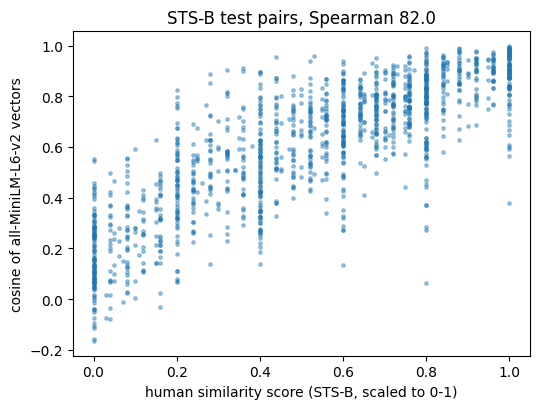

In [11]:
stsb = pd.read_csv(fetch("data/stsb_test.csv"))


def sts_spearman(encode):
    a, b = encode(stsb.sentence1.tolist()), encode(stsb.sentence2.tolist())
    return stats.spearmanr((a * b).sum(1), stsb.score).correlation


tfidf_sts = TfidfVectorizer(sublinear_tf=True).fit(pd.concat([stsb.sentence1, stsb.sentence2]))
sts_rows = {"TF-IDF (bag of words)": stats.spearmanr(np.asarray(tfidf_sts.transform(stsb.sentence1).multiply(tfidf_sts.transform(stsb.sentence2)).sum(1)).ravel(), stsb.score).correlation}
a_mean, a_cls = encode_raw(stsb.sentence1.tolist(), pooling=("mean", "cls"))
b_mean, b_cls = encode_raw(stsb.sentence2.tolist(), pooling=("mean", "cls"))
sts_rows["raw MiniLM, mean pooling"] = stats.spearmanr((a_mean * b_mean).sum(1), stsb.score).correlation
sts_rows["raw MiniLM, CLS token"] = stats.spearmanr((a_cls * b_cls).sum(1), stsb.score).correlation
for name, enc in encoders.items():
    sts_rows[name] = sts_spearman(enc)
sts_table = pd.Series(sts_rows, name="Spearman x 100").mul(100).round(1).to_frame()

a, b = encoders["all-MiniLM-L6-v2"](stsb.sentence1.tolist()), encoders["all-MiniLM-L6-v2"](stsb.sentence2.tolist())
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(stsb.score, (a * b).sum(1), s=6, alpha=0.4)
ax.set_xlabel("human similarity score (STS-B, scaled to 0-1)")
ax.set_ylabel("cosine of all-MiniLM-L6-v2 vectors")
ax.set_title(f"STS-B test pairs, Spearman {sts_rows['all-MiniLM-L6-v2'] * 100:.1f}")
plt.tight_layout()
sts_table

The raw MiniLM (51) is far *below* a plain word count (70): STS-B pairs share many words, so TF-IDF is a strong
baseline here, and the raw vectors rank the pairs worse than that. The same network after contrastive training
reaches 82, above the NLI-trained Sentence-BERT of 2019 (77) and below one trained on STS-B pairs (85), and
bge-small, trained on more and better pairs, 86. Lesson of this section: **an embedding model is a model trained
for similarity.** How that training works, and how much of it is needed, is section 4. First we need a yardstick
that matters in practice: search.

## 3. Semantic search, measured

This is the retrieval half of a RAG system (Lecture 08 adds the generation half):

```
offline:  documents ──► chunks ──► embedding model ──► vectors (index)
online:   question ──► embedding model ──► query vector ──► top-k most similar chunks ──► language model ──► answer
                                                           └──────── measured here ────────┘
```

The benchmark of Lecture 05: a **corpus** of 10 000 Quora questions and 1 000 **queries**, each with one to five
duplicates in the corpus (questions that Quora's moderators marked as asking the same thing). The queries were never
part of the training data we will use later. Lecture 05, section 4, has the long version of this section.

In [12]:
ret = pd.read_csv(fetch("data/quora_retrieval.csv", "L05_embeddings"))
queries = ret[ret.role == "query"].reset_index(drop=True)
corpus = ret[ret.role == "corpus"].reset_index(drop=True)
relevant = [np.flatnonzero(corpus.group.values == g) for g in queries.group]
print(f"{len(queries)} queries, {len(corpus)} documents, {sum(map(len, relevant))} relevant documents "
      f"({np.mean([len(r) for r in relevant]):.2f} per query); largest possible recall@1: {np.mean([1 / len(r) for r in relevant]):.3f}")
for k in (1, 5):
    print(f"\nquery:    {queries.text[k]}")
    for d in relevant[k]:
        print(f"relevant: {corpus.text[d]}")

1000 queries, 10000 documents, 1275 relevant documents (1.27 per query); largest possible recall@1: 0.897

query:    How can I make a perfect BBQ steak?
relevant: What makes a perfect steak?

query:    What is the best university degree for data science, and at which university?
relevant: What are the best schools for a degree in data science?


### Four retrievers and three metrics

- **TF-IDF**: sparse bag-of-words vectors, cosine similarity; only exact word matches count.
- **BM25** (Robertson et al., 1994; the default of Lucene and Elasticsearch): word matching with term-frequency
  saturation and document-length normalisation; still the keyword baseline to beat. Ten lines by hand below.
- **Dense retrieval**: cosine of embedding vectors; here `all-MiniLM-L6-v2` and `bge-small-en-v1.5`.
- **Hybrid**: reciprocal rank fusion of BM25 and a dense model, $\text{RRF}(d) = \sum_r 1 / (60 + \text{rank}_r(d))$
  (Cormack et al., 2009).

For a query with relevant set $R$ and a ranked list: **recall@k** is the share of $R$ in the top $k$ (what is not
retrieved cannot be used by the language model; with two duplicates and one slot, recall@1 cannot exceed one half,
so its ceiling on this data is 0.897); **hit@1** is whether the first result is relevant; **MRR@10** is
$1/\text{rank}$ of the first relevant result, averaged over queries (0 if it is not in the top 10).

**Before running:** will the dense models beat BM25 on recall@10, and by how much? Can the hybrid be worse than the
better of its two parts?

In [13]:
class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.vec = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
        tf = self.vec.fit_transform(docs).tocoo().astype(np.float64)        # documents x words, raw counts
        n_docs, df = tf.shape[0], np.bincount(tf.col, minlength=tf.shape[1])
        idf = np.log(1 + (n_docs - df + 0.5) / (df + 0.5))
        dl = np.asarray(tf.sum(1)).ravel()
        weight = tf.data * (k1 + 1) / (tf.data + k1 * (1 - b + b * dl[tf.row] / dl.mean())) * idf[tf.col]
        self.W = sparse.csr_matrix((weight, (tf.row, tf.col)), shape=tf.shape)

    def scores(self, texts):
        q = self.vec.transform(texts)
        q.data[:] = 1.0                                   # a query word counts once, however often it occurs
        return np.asarray((q @ self.W.T).todense())


def ranks_of_relevant(S):
    order = np.argsort(-S, axis=1)                        # rank (1 = best) of every relevant document for every query
    pos = np.empty_like(order)
    pos[np.arange(len(S))[:, None], order] = np.arange(S.shape[1])[None, :] + 1
    return [pos[q, r] for q, r in enumerate(relevant)]


def evaluate(S, name, ks=(1, 5, 10, 100)):
    rk = ranks_of_relevant(S)
    row = {"retriever": name}
    for k in ks:
        row[f"recall@{k}"] = np.mean([np.mean(r <= k) for r in rk])
    first = np.array([r.min() for r in rk])
    row["hit@1"] = np.mean(first == 1)
    row["MRR@10"] = np.mean(np.where(first <= 10, 1 / first, 0))
    return row, first


def rrf(*score_matrices, k=60, depth=100):
    fused = np.zeros_like(score_matrices[0])
    rows_ = np.arange(len(fused))[:, None]
    for S in score_matrices:
        top = np.argsort(-S, axis=1)[:, :depth]
        fused[rows_, top] += 1.0 / (k + np.arange(1, depth + 1))[None, :]
    return fused


def cached_embeddings(filename, compute):
    # GPU: encode the benchmark and keep the vectors; CPU: download the vectors computed by the same code on a GPU
    path = OUT_DIR / filename
    if TRAIN and not path.exists():
        Q, D = compute(queries.text.tolist()), compute(corpus.text.tolist())
        np.savez_compressed(path, queries=Q.astype(np.float16), corpus=D.astype(np.float16))
    z = np.load(fetch(path.as_posix()))
    return z["queries"].astype(np.float32), z["corpus"].astype(np.float32)

In [14]:
tfidf = TfidfVectorizer(sublinear_tf=True).fit(corpus.text)
S_tfidf = (tfidf.transform(queries.text) @ tfidf.transform(corpus.text).T).toarray()
bm25 = BM25(corpus.text)
S_bm25 = bm25.scores(queries.text)
Q_minilm, D_minilm = cached_embeddings("emb_quora_all_minilm.npz", encoders["all-MiniLM-L6-v2"])
Q_bge, D_bge = cached_embeddings("emb_quora_bge_small.npz", encoders["bge-small-en-v1.5"])
S_minilm, S_bge = Q_minilm @ D_minilm.T, Q_bge @ D_bge.T

results, first_rank, scores_by_name = [], {}, {}
for name, S in [("TF-IDF", S_tfidf), ("BM25", S_bm25), ("dense: all-MiniLM-L6-v2", S_minilm), ("dense: bge-small-en-v1.5", S_bge),
                ("hybrid: BM25 + bge-small (RRF)", rrf(S_bm25, S_bge))]:
    row, first_rank[name] = evaluate(S, name)
    results.append(row)
    scores_by_name[name] = S
pd.DataFrame(results).set_index("retriever").round(3)

,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10
retriever,,,,,,
TF-IDF,0.829,0.970,0.984,0.997,0.922,0.949
BM25,0.837,0.967,0.980,0.996,0.931,0.952
dense: all-MiniLM-L6-v2,0.884,0.996,1.000,1.000,0.986,0.992
dense: bge-small-en-v1.5,0.891,0.999,1.000,1.000,0.994,0.997
hybrid: BM25 + bge-small (RRF),0.870,0.985,0.994,1.000,0.971,0.981


**Before reading on:** the dense models win, but one of the two numbers is less trustworthy than the other. Which, and
why? (Answer in section 4.) The differences come from a few dozen harder queries; two of each kind:

In [15]:
def show_disagreement(winner, loser, n=2):
    gain = first_rank[loser] - first_rank[winner]
    for q in np.argsort(-gain)[:n]:
        top = np.argmax(scores_by_name[loser][q])
        best_rel = relevant[q][np.argmax(scores_by_name[winner][q, relevant[q]])]
        print(f"query:      {queries.text[q]}")
        print(f"relevant:   {corpus.text[best_rel]}   (rank {first_rank[winner][q]} with {winner}, rank {first_rank[loser][q]} with {loser})")
        print(f"{loser} top-1: {corpus.text[top]}\n")


print("=== the dense model finds it, BM25 does not ===\n")
show_disagreement("dense: bge-small-en-v1.5", "BM25")
print("=== BM25 finds it, the dense model does not ===\n")
show_disagreement("BM25", "dense: bge-small-en-v1.5")

=== the dense model finds it, BM25 does not ===

query:      Which is the best way to download movies?
relevant:   How can I download movie?   (rank 1 with dense: bge-small-en-v1.5, rank 273 with BM25)
BM25 top-1: Which is the best way to learn assembly language?

query:      Which is the best site to learn coding online for beginners?
relevant:   What is the best website to learn code as a beginner?   (rank 1 with dense: bge-small-en-v1.5, rank 88 with BM25)
BM25 top-1: Which is best book to learn R-programming for beginners?

=== BM25 finds it, the dense model does not ===

query:      What's all about life?
relevant:   What is Life? Is it all about buying a house to settle?   (rank 1 with BM25, rank 2 with dense: bge-small-en-v1.5)
dense: bge-small-en-v1.5 top-1: What is life? Is there any meaning to life? Why are we born on earth?

query:      How do entrepreneurs come up with new startup ideas?
relevant:   How do people come up with new ideas/be creative?   (rank 1 with BM25, rank

Dense vectors handle paraphrases (different words, same meaning). BM25 does no stemming, so *movies* and *movie* are
different words to it, and the frequent words of a query (*which is the best way to*) pull in unrelated questions
that share them. On these short questions the dense model is rarely far off: where BM25 wins,
the relevant question is still second on the dense list. Keyword search earns its place on rare exact terms, names,
codes and numbers, which a small embedding model blurs into a general topic (Lecture 05 shows such cases). The hybrid
is a compromise to be **measured on your own data**, not a guaranteed improvement: here it is *worse* than the dense
model alone, because rank fusion gives the weaker BM25 an equal vote.

**Your turn:** search the corpus with your own question.

In [16]:
def search(query, top=5):
    s_dense = encoders["bge-small-en-v1.5"]([query]) @ D_bge.T
    s_bm25 = bm25.scores([query])[0]
    out = pd.DataFrame({"dense (bge-small)": [f"{s_dense[0, k]:.3f}  {corpus.text[k]}" for k in np.argsort(-s_dense[0])[:top]],
                        "BM25": [f"{s_bm25[k]:.1f}  {corpus.text[k]}" for k in np.argsort(-s_bm25)[:top]]})
    with pd.option_context("display.max_colwidth", 90):
        display(out)


search("Which programming language should a beginner learn first?")

,dense (bge-small),BM25
0,0.907 Which programming languages should I start learning?,"22.9 Which Programming Language Should I Learn, C# Or C++?"
1,0.895 What is the best programming language one should start with?,21.9 What is the first programming languange to learn for a total beginner?
2,0.883 What is the first programming languange to learn for a total beginner?,19.8 Which programming Languages should I learn?
3,0.873 Which programming Languages should I learn?,17.9 Which backend programming language is the best to learn and why?
4,0.861 What is the programming language to learn?,17.8 What is the programming language to learn?


## 4. Contrastive fine-tuning, live

### The loss

Section 2 claimed that contrastive training turns a language model into an embedding model. We do it now, on the raw
MiniLM, with 20 000 pairs of duplicate questions from the full Quora data set (none of them in the benchmark above).
A batch holds $B$ pairs $(q_i, d_i)$. With unit vectors and the cosine matrix $S_{ij} = \mathbf{q}_i \cdot \mathbf{d}_j$,
the loss asks every question to rank *its own* duplicate first among the $B$ candidates:

$$\mathcal{L} = -\frac{1}{B}\sum_{i=1}^{B} \log \frac{\exp(S_{ii} / \tau)}{\sum_{j=1}^{B} \exp(S_{ij} / \tau)},$$

a cross-entropy over the batch with temperature $\tau$ (here $1/20$). The other pairs of the batch serve as
**in-batch negatives**: no labelled negatives are needed. This is exactly the loss of CLIP (Lecture 05) with
sentences on both sides, and the same idea as negative sampling in word2vec (Lecture 06). The code below averages
this loss with its transpose (every duplicate has to find its question too), as CLIP does; `MultipleNegativesRankingLoss`
in `sentence-transformers` uses the one direction written above with the same scale of 20. We write it in two lines
and train in twenty.

In [17]:
train_pairs = pd.read_csv(fetch("data/quora_train_pairs.csv"))
print(len(train_pairs), "training pairs, e.g.")
display(train_pairs.sample(3, random_state=SEED))


def contrastive_loss(Q, D, scale=20.0):
    S = Q @ D.T * scale                                   # B x B cosine matrix, the diagonal holds the true pairs
    labels = torch.arange(len(S), device=S.device)
    return (F.cross_entropy(S, labels) + F.cross_entropy(S.T, labels)) / 2      # both directions, as in CLIP


def encode_train(model, texts, max_len=32):
    batch = raw_tok(list(texts), padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
    return pool(batch, model(**batch).last_hidden_state)           # gradients flow through the pooling


def train_contrastive(model, pairs, epochs=1, batch_size=64, lr=5e-5, log_every=25):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    rng = np.random.default_rng(SEED)
    history, step, t0 = [], 0, time.time()
    model.train()
    for epoch in range(epochs):
        order = rng.permutation(len(pairs))
        for i in range(0, len(order) - batch_size + 1, batch_size):
            idx = order[i:i + batch_size]
            loss = contrastive_loss(encode_train(model, pairs.question1.values[idx]), encode_train(model, pairs.question2.values[idx]))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if log_every and step % log_every == 0:
                history.append((step, loss.item()))
                print(f"step {step:4d} | loss {loss.item():.3f} | {time.time() - t0:5.1f} s")
            step += 1
    model.eval()
    return history, time.time() - t0

20000 training pairs, e.g.


,question1,question2
10650,"How can I develop, test and run Android apps if I have a Windows phone?",How can I install Android apps on my windows phone?
2041,What are examples of animals with vertebrates?,What are some examples of vertebrates?
8668,Can people actively control their emotions?,Does our mind control our emotions?


Before training, the cosine matrix of one batch of eight pairs: the diagonal should be bright and the rest dark, and
for the raw model it is not. We also record the yardsticks: STS-B and the Quora benchmark with the raw model.

In [18]:
demo = train_pairs.sample(8, random_state=1)


@torch.no_grad()
def batch_matrix(encode):
    return encode(demo.question1.tolist()) @ encode(demo.question2.tolist()).T


def retrieval_metrics(encode, name):
    Q, D = encode(queries.text.tolist()), encode(corpus.text.tolist())
    row, _ = evaluate(Q @ D.T, name)
    return row, Q, D


FT_JSON, FT_EMB = OUT_DIR / "finetune_minilm.json", OUT_DIR / "emb_quora_finetuned.npz"
if TRAIN and (RETRAIN or not FT_JSON.exists()):
    before = {"batch_matrix": batch_matrix(encode_raw).tolist(), "sts": sts_spearman(encode_raw),
              "retrieval": retrieval_metrics(encode_raw, "raw MiniLM, mean pooling")[0],
              "random_cosines": cosines["raw MiniLM, mean pooling"]["random"].tolist()}
else:
    before = None
print("raw MiniLM before training: STS-B Spearman", round(sts_rows["raw MiniLM, mean pooling"] * 100, 1))

raw MiniLM before training: STS-B Spearman 51.1


### Training

One pass over the 20 000 pairs in batches of 64 (312 steps). **Before running:** with the raw model 89 % of the
relevant documents are already in the top 10 (recall@10; the ordering survives the cone, section 2), but only 78 %
of the queries have a duplicate in first place (hit@1) and MRR@10 is 0.82; guess the three numbers after this one
epoch.

step    0 | loss 2.699 |   0.1 s


step   25 | loss 0.196 |   1.3 s


step   50 | loss 0.187 |   2.4 s


step   75 | loss 0.108 |   3.5 s


step  100 | loss 0.123 |   4.6 s


step  125 | loss 0.069 |   5.7 s


... (3 outputs left out)

step  225 | loss 0.059 |  10.3 s


step  250 | loss 0.122 |  11.4 s


step  275 | loss 0.049 |  12.5 s


step  300 | loss 0.102 |  13.6 s


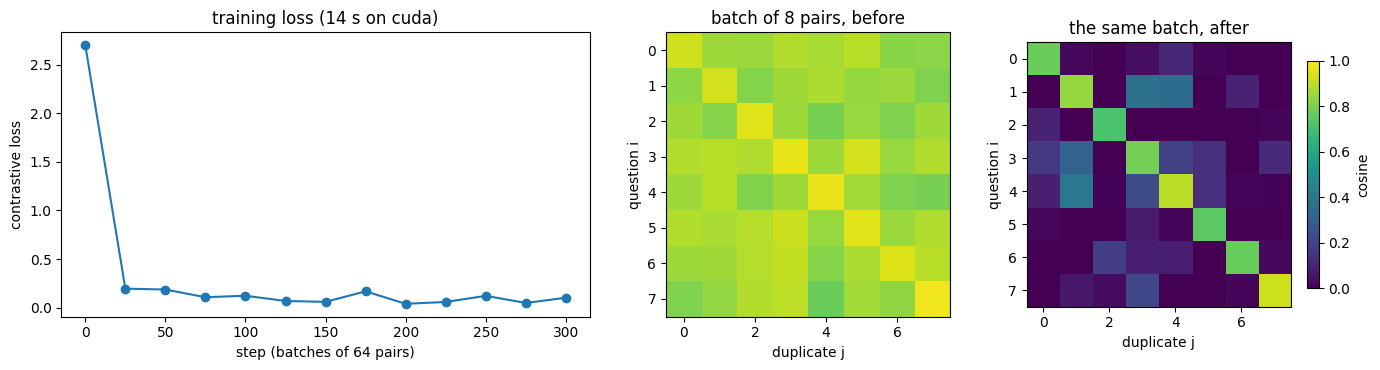

In [19]:
if TRAIN and (RETRAIN or not FT_JSON.exists()):
    torch.manual_seed(SEED)
    ours = AutoModel.from_pretrained(RAW_NAME).to(device)
    loss_history, train_time = train_contrastive(ours, train_pairs)
    encode_ours = lambda texts: encode_raw(texts, model=ours)
    after_row, Q_ours, D_ours = retrieval_metrics(encode_ours, "our MiniLM, 1 epoch on 20k Quora pairs")
    after = {"batch_matrix": batch_matrix(encode_ours).tolist(), "sts": sts_spearman(encode_ours), "retrieval": after_row,
             "random_cosines": (encode_ours(rand.question1.tolist()) * encode_ours(rand.question2.tolist())).sum(1).tolist()}
    record = {"before": before, "after": after, "loss": loss_history, "train_time": train_time, "device": str(device),
              "pairs": len(train_pairs), "demo_pairs": demo.values.tolist()}
    np.savez_compressed(FT_EMB, queries=Q_ours.astype(np.float16), corpus=D_ours.astype(np.float16))
    with open(FT_JSON, "w") as f:
        json.dump(record, f)
else:
    ours = None                                   # no GPU (or the results exist already): use the stored results of this very code
    with open(fetch(FT_JSON.as_posix())) as f:
        record = json.load(f)
    z = np.load(fetch(FT_EMB.as_posix()))
    Q_ours, D_ours = z["queries"].astype(np.float32), z["corpus"].astype(np.float32)
    before, after, loss_history = record["before"], record["after"], record["loss"]
    print(f"loaded the results of a training run on {record['device']}: {record['pairs']} pairs, {record['train_time']:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].plot(*zip(*loss_history), "o-")
axes[0].set_xlabel("step (batches of 64 pairs)")
axes[0].set_ylabel("contrastive loss")
axes[0].set_title(f"training loss ({record['train_time']:.0f} s on {record['device']})")
for ax, (title, M) in zip(axes[1:], [("batch of 8 pairs, before", before["batch_matrix"]), ("the same batch, after", after["batch_matrix"])]):
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("duplicate j")
    ax.set_ylabel("question i")
plt.colorbar(im, ax=axes[2], shrink=0.8, label="cosine")
plt.tight_layout()

### The effect

Three yardsticks before and after one epoch: the cosines of unrelated pairs (anisotropy), STS-B, and the Quora
benchmark. For comparison the rows of the two pretrained models and of TF-IDF, the keyword method that has an STS-B
number too.

,STS-B Spearman x 100,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10
retriever,,,,,,,
"raw MiniLM, mean pooling",51.1,0.697,0.846,0.888,0.961,0.778,0.824
"our MiniLM, 1 epoch on 20k Quora pairs",70.6,0.866,0.986,0.993,0.999,0.967,0.978
TF-IDF,69.9,0.829,0.970,0.984,0.997,0.922,0.949
dense: all-MiniLM-L6-v2,82.0,0.884,0.996,1.000,1.000,0.986,0.992
dense: bge-small-en-v1.5,85.9,0.891,0.999,1.000,1.000,0.994,0.997


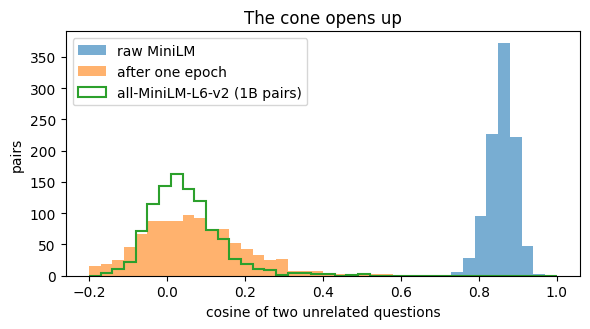

In [20]:
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(before["random_cosines"], bins=40, range=(-0.2, 1), alpha=0.6, label="raw MiniLM")
ax.hist(after["random_cosines"], bins=40, range=(-0.2, 1), alpha=0.6, label="after one epoch")
ax.hist(cosines["all-MiniLM-L6-v2"]["random"], bins=40, range=(-0.2, 1), histtype="step", lw=1.5, label="all-MiniLM-L6-v2 (1B pairs)")
ax.set_xlabel("cosine of two unrelated questions")
ax.set_ylabel("pairs")
ax.legend()
ax.set_title("The cone opens up")
plt.tight_layout()

summary = pd.DataFrame([before["retrieval"], after["retrieval"]] + [r for r in results if r["retriever"] in ("TF-IDF", "dense: all-MiniLM-L6-v2", "dense: bge-small-en-v1.5")]).set_index("retriever")
summary.insert(0, "STS-B Spearman x 100", np.round([before["sts"] * 100, after["sts"] * 100, sts_rows["TF-IDF (bag of words)"] * 100,
                                                    sts_rows["all-MiniLM-L6-v2"] * 100, sts_rows["bge-small-en-v1.5"] * 100], 1))
summary.round(3)

A few hundred gradient steps on 20 000 pairs take the raw model from 51 to 71 on STS-B (the level of the word-count
baseline) and from a mediocre to a strong retriever on the Quora benchmark: a duplicate in first place for 97 % of
the queries instead of 78 % (hit@1), recall@1 0.87 instead of 0.70, MRR 0.98 instead of 0.82, within two or three
points of the pretrained models. The remaining gap on STS-B (71 against 82 and 86) is the other billion pairs and a
broader data mix: our model has only seen questions. Note
that it has an advantage on this benchmark that bge-small does not have: it was trained on *Quora questions*
(in-domain data), though never on the benchmark queries themselves. That is legitimate and it is exactly what you
will do for your project: a few thousand pairs from your own domain.

### Clean versus contaminated evaluation *(optional)*

What would **not** be legitimate: training on the test pairs. The next cell trains a fresh raw MiniLM on *nothing but*
the 1 275 pairs (benchmark query, its duplicate in the corpus), five passes, about a hundred steps. **Before
running:** can a model that has seen only 1 275 pairs beat the one trained on 20 000?

In [21]:
CONT_JSON = OUT_DIR / "finetune_contaminated.json"
if TRAIN and (RETRAIN or not CONT_JSON.exists()):
    leak = pd.DataFrame([(queries.text[q], corpus.text[d]) for q, rel in enumerate(relevant) for d in rel], columns=["question1", "question2"])
    torch.manual_seed(SEED)
    contaminated = AutoModel.from_pretrained(RAW_NAME).to(device)
    _, t_cont = train_contrastive(contaminated, leak, epochs=5, log_every=None)
    row_cont, _, _ = retrieval_metrics(lambda texts: encode_raw(texts, model=contaminated), "raw MiniLM trained on the 1 275 test pairs only")
    row_cont["STS-B Spearman x 100"] = round(sts_spearman(lambda texts: encode_raw(texts, model=contaminated)) * 100, 1)
    with open(CONT_JSON, "w") as f:
        json.dump({"retrieval": row_cont, "n_leak": len(leak), "train_time": t_cont}, f)
    del contaminated
with open(fetch(CONT_JSON.as_posix())) as f:
    cont = json.load(f)
pd.DataFrame([dict(after["retrieval"], **{"STS-B Spearman x 100": round(after["sts"] * 100, 1)}), cont["retrieval"]]).set_index("retriever").round(3)

,recall@1,recall@5,recall@10,recall@100,hit@1,MRR@10,STS-B Spearman x 100
retriever,,,,,,,
"our MiniLM, 1 epoch on 20k Quora pairs",0.866,0.986,0.993,0.999,0.967,0.978,70.6
raw MiniLM trained on the 1 275 test pairs only,0.874,0.997,0.999,1.000,0.977,0.986,68.6


It can: on the benchmark the model that memorised the test pairs is the better one (recall@1, hit@1 and MRR all
higher) although it is the worse model everywhere else (lower STS-B, and it has seen 1 275 pairs instead of
20 000). A benchmark number of a model that was trained on the benchmark measures memory, not generalisation. This
is the leakage of Lecture 03 in a new disguise, and it is why published scores of embedding models deserve
suspicion: `all-MiniLM-L6-v2` lists 100 000 Quora question triplets among its training pairs, so its row in section 3
is partly a memory test (whether the same holds for bge-small is less clear from its model card, which is exactly the
problem); the current MTEB benchmark (v2, 2025) dropped the Quora task and its leaderboard marks for every model
whether a score is *zero-shot*, i.e. obtained without training data from that task. When you evaluate a model for
your project, evaluate it on pairs it has never seen, and when you fine-tune, keep the test pairs out of the training
set.

**Your turn** (GPU): set `RETRAIN = True` in the setup cell, change `lr`, `batch_size` or the number of epochs in the
training cell and watch the benchmark; a batch of 16 gives fewer in-batch negatives and a weaker model.

## 5. Fine-tuning an encoder for classification

Transfer learning for text follows the three regimes of Lecture 04 (feature extraction, head only, full fine-tuning).
For a linear head, *head only* and *frozen features + logistic regression* are the same model, so regime (b) below
covers both, and (a) is the baseline without any pretrained model. The task is sentiment of **Czech film reviews**
from ČSFD (5 000 reviews with a star rating; 0–1 stars = negative, 4–5 stars = positive; 4 000 for training, 1 000
for the test, balanced). The encoder is **RetroMAE-small-cs** by Seznam.cz (Bednář et al., 2024): 24M parameters,
256-dimensional vectors, pretrained on Czech web text; its sibling `simcse-retromae-small-cs` is the same network
after contrastive training on Czech sentence pairs, the Czech counterpart of the MiniLM pair of section 2. Both use
the `[CLS]` vector. The regularisation of the logistic regressions in (a) and (b) is chosen by cross-validation on
the training reviews; the test reviews are used once, at the end.

| regime | what is trained | cost |
|---|---|---|
| (a) bag of words | TF-IDF + logistic regression | seconds, CPU |
| (b) frozen encoder + linear head | logistic regression on the `[CLS]` vector of the raw encoder, and of the contrastive one | seconds after one encoding pass |
| (c) full fine-tuning | all 24M parameters + a new head, 4 epochs | one to two minutes on a T4 |

**Before running:** rank the four rows by test accuracy.

In [22]:
CS_RAW, CS_SIMCSE = "Seznam/retromae-small-cs", "Seznam/simcse-retromae-small-cs"
csfd = pd.read_csv(fetch("data/csfd_reviews.csv"))
cs_train, cs_test = csfd[csfd.split == "train"].reset_index(drop=True), csfd[csfd.split == "test"].reset_index(drop=True)
print(f"{len(cs_train)} training and {len(cs_test)} test reviews, median length {csfd.text.str.len().median():.0f} characters")
display(cs_train.sample(3, random_state=SEED)[["rating", "label", "text"]])

cs_tok = AutoTokenizer.from_pretrained(CS_RAW)
cs_raw = AutoModel.from_pretrained(CS_RAW).to(device).eval()
cs_simcse = AutoModel.from_pretrained(CS_SIMCSE).to(device).eval()
print("tokens:", cs_tok.tokenize(cs_train.text[0])[:14])

# (a) bag of words (words and bigrams); the regularisation C is chosen by 5-fold cross-validation on the training reviews
tfidf_cs = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2).fit(cs_train.text)
lr_tfidf = LogisticRegressionCV(Cs=[0.3, 1, 3, 10], cv=5, max_iter=2000).fit(tfidf_cs.transform(cs_train.text), cs_train.label)
test_probs = {"(a) TF-IDF + logistic regression": lr_tfidf.predict_proba(tfidf_cs.transform(cs_test.text))[:, 1]}
print(f"(a) {tfidf_cs.transform(cs_train.text).shape[1]:,} features, C = {lr_tfidf.C_[0]:g}")

# (b) frozen encoders: one encoding pass over the reviews (cut at 256 tokens, cached for the CPU path), then a linear model
EMB_CS = OUT_DIR / "emb_csfd.npz"
if TRAIN and not EMB_CS.exists():
    feats = {}
    for tag, model in [("raw", cs_raw), ("simcse", cs_simcse)]:
        for split, df in [("train", cs_train), ("test", cs_test)]:
            feats[f"{tag}_{split}"] = encode_raw(df.text.tolist(), model, cs_tok, pooling="cls", batch_size=64, max_len=256).astype(np.float16)
    np.savez_compressed(EMB_CS, **feats)
feats = {k: v.astype(np.float32) for k, v in np.load(fetch(EMB_CS.as_posix())).items()}
lr_frozen = {}
for tag, label in [("raw", "(b) frozen raw RetroMAE [CLS] + logistic regression"), ("simcse", "(b) frozen SimCSE-RetroMAE [CLS] + logistic regression")]:
    lr_frozen[tag] = LogisticRegressionCV(Cs=[0.3, 1, 3, 10], cv=5, max_iter=2000).fit(feats[f"{tag}_train"], cs_train.label)
    test_probs[label] = lr_frozen[tag].predict_proba(feats[f"{tag}_test"])[:, 1]
    print(f"(b) {tag}: C = {lr_frozen[tag].C_[0]:g}")

4000 training and 1000 test reviews, median length 247 characters


,rating,label,text
555,4,1,Romantická tabulka příběhu ochucená špetkou hořkých událostí na pozadí sladkého nádechu pohádkovosti se zamilovanou ...
3491,5,1,"Za mě rozhodně slabší pětka. I když to vlastně vůbec není o veselých věcech, je ten film hrozná pohoda a zábava. Jas..."
527,0,0,"každé dvě minuty filmu, by byly slušným trailerem a možná by i přitáhly diváky, takhle pěkně jednotlivě... možná i j..."


tokens: ['čím', 'delší', 'dobu', 'film', 'běže', '##l', ',', 'tím', 'víc', 'jsem', 'si', 'říkala', ',', 'co']


(a) 29,176 features, C = 10


(b) raw: C = 10


(b) simcse: C = 3


### (c) Full fine-tuning

The classifier is the encoder plus one linear layer on the `[CLS]` vector; the loss is the binary cross-entropy of
Lecture 04. Reviews are cut at 256 tokens (one in twenty is longer). We keep 500 training reviews as a validation
split for choosing the epoch by validation accuracy (and, when preparing this notebook, the learning rate and the
input length), and touch the test reviews once at the end.

epoch 1 | train loss 0.569 acc 0.697 | val loss 0.423 acc 0.798 |    7 s


epoch 2 | train loss 0.357 acc 0.841 | val loss 0.470 acc 0.820 |   13 s


epoch 3 | train loss 0.260 acc 0.892 | val loss 0.430 acc 0.818 |   19 s


epoch 4 | train loss 0.189 acc 0.922 | val loss 0.414 acc 0.856 |   26 s


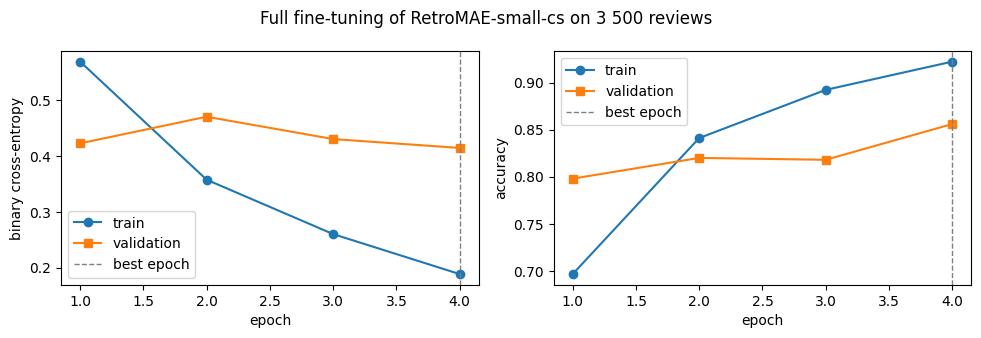

In [23]:
class ReviewClassifier(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(name)
        self.head = nn.Linear(self.encoder.config.hidden_size, 1)

    def forward(self, **batch):
        return self.head(self.encoder(**batch).last_hidden_state[:, 0]).squeeze(-1)      # one logit from the [CLS] vector


def run_epoch(model, texts, labels, optimizer=None, batch_size=32, max_len=256):
    training = optimizer is not None
    model.train(training)
    order = np.random.permutation(len(texts)) if training else np.arange(len(texts))
    total, correct, probs = 0.0, 0, np.zeros(len(texts))
    with torch.set_grad_enabled(training):
        for i in range(0, len(texts), batch_size):
            idx = order[i:i + batch_size]
            batch = cs_tok([texts[j] for j in idx], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
            y = torch.tensor(labels[idx], dtype=torch.float32, device=device)
            logits = model(**batch)
            loss = F.binary_cross_entropy_with_logits(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(idx)
            correct += ((logits > 0) == (y > 0.5)).sum().item()
            probs[idx] = torch.sigmoid(logits).detach().cpu().numpy()
    return total / len(texts), correct / len(texts), probs


CLS_JSON = OUT_DIR / "classification_csfd.json"
if TRAIN and (RETRAIN or not CLS_JSON.exists()):
    fit_text, val_text, fit_y, val_y = train_test_split(cs_train.text.tolist(), cs_train.label.values, test_size=500, stratify=cs_train.label, random_state=SEED)
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    clf = ReviewClassifier(CS_RAW).to(device)
    optimizer = torch.optim.AdamW(clf.parameters(), lr=5e-5, weight_decay=0.01)
    history, best, t0 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}, (-1.0, None, 0), time.time()
    for epoch in range(1, 5):
        tr_loss, tr_acc, _ = run_epoch(clf, fit_text, np.asarray(fit_y), optimizer)
        va_loss, va_acc, _ = run_epoch(clf, val_text, np.asarray(val_y))
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        if va_acc >= best[0]:                                  # keep the epoch with the best validation accuracy
            best = (va_acc, {k: v.detach().cpu().clone() for k, v in clf.state_dict().items()}, epoch)
        print(f"epoch {epoch} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:4.0f} s")
    clf.load_state_dict(best[1])
    _, _, p_test = run_epoch(clf, cs_test.text.tolist(), cs_test.label.values)
    cls_record = {"history": history, "best_epoch": best[2], "test_probs": p_test.tolist(), "train_time": time.time() - t0, "device": str(device)}
    with open(CLS_JSON, "w") as f:
        json.dump(cls_record, f)
else:
    clf = None
    with open(fetch(CLS_JSON.as_posix())) as f:
        cls_record = json.load(f)
    print(f"loaded the results of a training run on {cls_record['device']}: best epoch {cls_record['best_epoch']}, {cls_record['train_time']:.0f} s")
test_probs["(c) full fine-tuning of RetroMAE"] = np.asarray(cls_record["test_probs"])

h = cls_record["history"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, key, label in zip(axes, ("loss", "acc"), ("binary cross-entropy", "accuracy")):
    ax.plot(range(1, len(h["train_loss"]) + 1), h[f"train_{key}"], "o-", label="train")
    ax.plot(range(1, len(h["train_loss"]) + 1), h[f"val_{key}"], "s-", label="validation")
    ax.axvline(cls_record["best_epoch"], color="grey", ls="--", lw=1, label="best epoch")
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.legend()
fig.suptitle("Full fine-tuning of RetroMAE-small-cs on 3 500 reviews")
plt.tight_layout()

,test accuracy,test ROC-AUC
regime,,
(a) TF-IDF + logistic regression,0.860,0.934
(b) frozen raw RetroMAE [CLS] + logistic regression,0.814,0.891
(b) frozen SimCSE-RetroMAE [CLS] + logistic regression,0.803,0.890
(c) full fine-tuning of RetroMAE,0.863,0.945


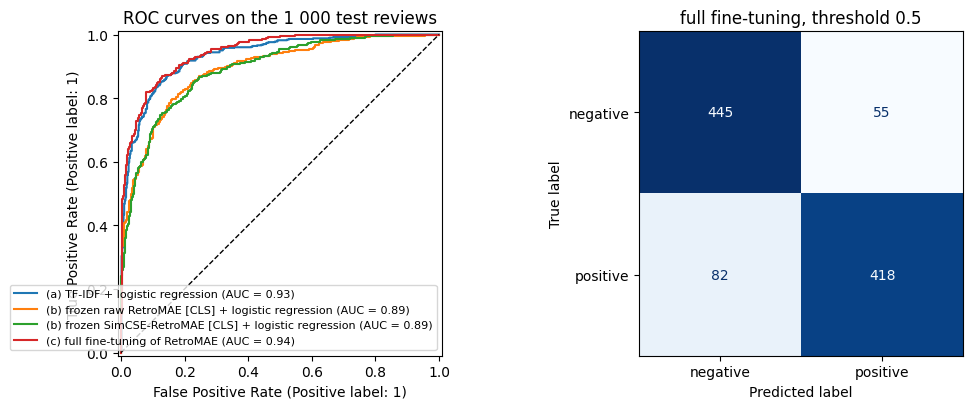

In [24]:
rows = [{"regime": name, "test accuracy": accuracy_score(cs_test.label, p >= 0.5), "test ROC-AUC": roc_auc_score(cs_test.label, p)}
        for name, p in test_probs.items()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p in test_probs.items():
    RocCurveDisplay.from_predictions(cs_test.label, p, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves on the 1 000 test reviews")
axes[0].legend(fontsize=8, loc="lower right")
ConfusionMatrixDisplay(confusion_matrix(cs_test.label, test_probs["(c) full fine-tuning of RetroMAE"] >= 0.5),
                       display_labels=["negative", "positive"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("full fine-tuning, threshold 0.5")
plt.tight_layout()
pd.DataFrame(rows).set_index("regime").round(3)

Not quite the ranking of Lecture 04. The bag of words is a very strong baseline here (about 86 % accuracy):
sentiment is carried by specific words and bigrams (*skvělý*, *nuda*, *ztráta času*), which TF-IDF sees directly in
the full review, and 4 000 examples are plenty for a linear model on them. The frozen `[CLS]` vectors lose by about
five points, the contrastive one included: a 256-dimensional vector trained for *similarity* keeps what two reviews
have in common (the film, the topic) and compresses away their polarity, and the raw encoder was never trained to
summarise a text at all. Full fine-tuning rewires the encoder for the task and lands at the level of the bag of
words, a point or two above or below it depending on the run: fine-tuning 24 million parameters on 3 500 reviews is
noisy (the validation accuracy moves by several points from epoch to epoch, and the standard error of an accuracy on
1 000 test reviews is about one point), so a single run cannot separate the two, and an honest comparison repeats
the fine-tuning with several seeds. The practical order is the one of Lecture 04 nevertheless: baseline first
(seconds), frozen features second (seconds, and the better choice on tasks about *meaning*: intent, topic,
paraphrase), full fine-tuning when labels are plentiful and the gain is measured on held-out data.

**Your turn:** classify your own Czech sentence (both the frozen SimCSE model and, on a GPU, the fine-tuned one). The
first example below is a mixed review that ends negatively; both models tend to call it positive, fooled by the
opening clause. With a GPU, `RETRAIN = True` in the setup cell trains the classifier again with your own settings.

In [25]:
@torch.no_grad()
def sentiment(text):
    e = encode_raw([text], cs_simcse, cs_tok, pooling="cls", max_len=256)
    p_frozen = lr_frozen["simcse"].predict_proba(e)[0, 1]
    line = f"{text!r}\n   frozen SimCSE + logistic regression: P(positive) = {p_frozen:.2f}"
    if clf is not None:
        clf.eval()
        batch = cs_tok([text], return_tensors="pt", truncation=True, max_length=256).to(device)
        line += f"\n   fine-tuned RetroMAE:                 P(positive) = {torch.sigmoid(clf(**batch)).item():.2f}"
    print(line)


sentiment("Herecké výkony byly skvělé, ale scénář nedával smysl a konec mě zklamal.")
sentiment("Nejlepší film, jaký jsem letos viděl.")

'Herecké výkony byly skvělé, ale scénář nedával smysl a konec mě zklamal.'
   frozen SimCSE + logistic regression: P(positive) = 0.88
   fine-tuned RetroMAE:                 P(positive) = 0.92
'Nejlepší film, jaký jsem letos viděl.'
   frozen SimCSE + logistic regression: P(positive) = 0.91
   fine-tuned RetroMAE:                 P(positive) = 0.94


## 6. Checklist for your project and what comes next

**Choosing an embedding model**
- Use a model *trained for similarity* (the contrastive stage of section 4), never the hidden states of a plain
  language model; check the model card for the pooling, the maximum input length and required prefixes or
  instructions (`query:` / `passage:` for e5, an instruction line for Qwen3-Embedding and Harrier).
- Czech documents or Czech users: a multilingual model (`multilingual-e5-small`, `bge-m3`, `harrier-oss-v1-270m`)
  or a Czech one (the small Seznam models); Lecture 05, section 5, shows the difference on Czech queries.
- Look at the [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard) (state of November 2026: version 2
  of the benchmark, 41 English and 131 multilingual tasks) filtered by language and task, read the *zero-shot* column,
  check the licence (several strong models are non-commercial or gated), then **measure on your own pairs**: a few
  hundred (question, relevant chunk) pairs from your documents, recall@k and MRR as in section 3.
- Symmetric vs. asymmetric: a RAG question has to find a *passage that answers it*, not a similar question; evaluate on
  such pairs.

**Fine-tuning**
- A few thousand in-domain pairs and one epoch of the loss of section 4 already change a lot; `sentence-transformers`
  (`MultipleNegativesRankingLoss`, `SentenceTransformerTrainer`) does the same with hard-negative mining and evaluators.
- Keep the evaluation pairs out of the training data; a benchmark the model was trained on measures memory, not
  generalisation.
- For classification, start with TF-IDF and with frozen embeddings + logistic regression; fine-tune the whole encoder
  only when labels are plentiful and the gain is measured on held-out data (Lecture 04).

**What comes next**
- **Lecture 08: retrieval-augmented generation** end to end: chunking documents, approximate nearest-neighbour indexes,
  reranking the top-k with a cross-encoder (`cross-encoder/ms-marco-MiniLM-L6-v2`, `bge-reranker-v2-m3`), the
  language model of section 1 with retrieved passages in its prompt, hallucinations, and how to evaluate the whole
  pipeline; a small Gradio application.

**References**
- N. Reimers, I. Gurevych (2019), *Sentence-BERT: Sentence embeddings using Siamese BERT-networks*, EMNLP.
- D. Cer, M. Diab, E. Agirre, I. Lopez-Gazpio, L. Specia (2017), *SemEval-2017 Task 1: Semantic textual similarity*, SemEval (STS-B).
- K. Ethayarajh (2019), *How contextual are contextualized word representations?*, EMNLP.
- T. Gao, X. Yao, D. Chen (2021), *SimCSE: Simple contrastive learning of sentence embeddings*, EMNLP.
- S. Robertson, H. Zaragoza (2009), *The probabilistic relevance framework: BM25 and beyond*, Foundations and Trends in IR.
- G. Cormack, C. Clarke, S. Büttcher (2009), *Reciprocal rank fusion outperforms Condorcet and individual rank learning methods*, SIGIR.
- N. Muennighoff et al. (2023), *MTEB: Massive text embedding benchmark*, EACL; K. Enevoldsen et al. (2025), *MMTEB*, ICLR.
- J. Bednář, J. Náplava, P. Barančíková, O. Lisický (2024), *Some like it small: Czech semantic embedding models for industry applications*, AAAI.
- Hugging Face documentation: [text generation strategies](https://huggingface.co/docs/transformers/generation_strategies),
  [sentence-transformers training](https://sbert.net/docs/sentence_transformer/training_overview.html).